# Project 1: The Five Classes of Learners (checkpoint)

1. Data visualization: `visualization.ipynb`
2. Evaluation methodology: this notebook

In [1]:
import numpy as np
import polars as pl
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
FEATURES = [
    "length", "diameter", "height", "whole_weight", "shucked_weight", "viscera_weight", "shell_weight",
    "is_infant", "is_female",
]

df = pl.read_csv("./data/abalone.csv.zst")
print(df.shape)

(4177, 9)


## 2. Evaluation methodology

### 2.1 Remove the 4 `height` outliers

Two rows have `height` = 0 (impossible: a shell has a thickness) and two have `height` above 0.3 (0.515 and 1.13, while the next largest value is 0.25).
The rule uses only domain knowledge, not a statistic learned from the data, so applying it before the split cannot leak anything.

In [2]:
is_outlier = (pl.col("height") == 0) | (pl.col("height") > 0.3)
print(df.filter(is_outlier).select(["sex", "length", "height", "rings"]))
df = df.filter(~is_outlier)
print("rows kept:", df.height)

shape: (4, 4)
┌─────┬────────┬────────┬───────┐
│ sex ┆ length ┆ height ┆ rings │
│ --- ┆ ---    ┆ ---    ┆ ---   │
│ str ┆ f64    ┆ f64    ┆ i64   │
╞═════╪════════╪════════╪═══════╡
│ I   ┆ 0.43   ┆ 0.0    ┆ 8     │
│ M   ┆ 0.705  ┆ 0.515  ┆ 10    │
│ F   ┆ 0.455  ┆ 1.13   ┆ 8     │
│ I   ┆ 0.315  ┆ 0.0    ┆ 6     │
└─────┴────────┴────────┴───────┘
rows kept: 4173


### 2.2 Encode `sex`

`sex` becomes two binary columns, `is_infant` and `is_female` (male is the reference, both 0), then the original `sex` column is dropped.
It is a fixed rule so doing it before the split cannot leak anything.

In [3]:
df = df.with_columns(
    is_infant=(pl.col("sex") == "I").cast(pl.Int8),
    is_female=(pl.col("sex") == "F").cast(pl.Int8),
)
print(df.group_by("sex", "is_infant", "is_female").agg(pl.len(), pl.col("rings").mean().round(2).alias("mean rings")).sort("sex"))
df = df.drop("sex")
print(df.columns)

shape: (3, 5)
┌─────┬───────────┬───────────┬──────┬────────────┐
│ sex ┆ is_infant ┆ is_female ┆ len  ┆ mean rings │
│ --- ┆ ---       ┆ ---       ┆ ---  ┆ ---        │
│ str ┆ i8        ┆ i8        ┆ u32  ┆ f64        │
╞═════╪═══════════╪═══════════╪══════╪════════════╡
│ F   ┆ 0         ┆ 1         ┆ 1306 ┆ 11.13      │
│ I   ┆ 1         ┆ 0         ┆ 1340 ┆ 7.89       │
│ M   ┆ 0         ┆ 0         ┆ 1527 ┆ 10.71      │
└─────┴───────────┴───────────┴──────┴────────────┘
['length', 'diameter', 'height', 'whole_weight', 'shucked_weight', 'viscera_weight', 'shell_weight', 'rings', 'is_infant', 'is_female']


### 2.3 Hold-out test set

20% of the rows are set aside first, stratified on the binned target (5 quantile bins of `rings`), with a fixed seed.
The test set is **not used again until the final evaluation**: every choice and every tuning step uses the development part only.

In [4]:
rings_all = df["rings"].to_numpy()
y_bins = np.digitize(rings_all, np.quantile(rings_all, [0.2, 0.4, 0.6, 0.8]))

dev_idx, test_idx = train_test_split(np.arange(df.height), test_size=0.2, random_state=SEED, stratify=y_bins)
dev, test = df[dev_idx], df[test_idx]
bins_dev = y_bins[dev_idx]

print(f"development: {dev.height} rows, mean rings {dev['rings'].mean():.2f}")
print(f"test:        {test.height} rows, mean rings {test['rings'].mean():.2f}")

development: 3338 rows, mean rings 9.94
test:        835 rows, mean rings 9.91


### 2.4 Five folds on the development part

Stratified 5-fold on the same binned target, shuffled, with a fixed seed, so every fold keeps the same mix of young and old animals.

In [5]:
rings = dev["rings"].to_numpy()
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(skf.split(np.zeros(len(rings)), bins_dev))

print("fold  train  validation  mean rings  std rings  max rings")
for k, (tr, va) in enumerate(folds):
    print(f"{k:4d}  {len(tr):5d}  {len(va):10d}  {rings[va].mean():10.2f}  {rings[va].std():9.2f}  {rings[va].max():9d}")

fold  train  validation  mean rings  std rings  max rings
   0   2670         668        9.89       3.14         23
   1   2670         668        9.92       3.20         23
   2   2670         668       10.08       3.48         25
   3   2671         667        9.95       3.23         27
   4   2671         667        9.86       3.07         23


### 2.5 Standardization, fitted inside each fold

In [6]:
X = dev.select(FEATURES).to_numpy()

scaled_folds = []
for tr, va in folds:
    scaler = StandardScaler().fit(X[tr])
    scaled_folds.append((scaler.transform(X[tr]), scaler.transform(X[va])))

### 2.6 Metrics and baseline

* **RMSE** (main): the typical error in rings, with large errors counting more.
* **MAE**: the average absolute error in rings, less sensitive to the few old animals.
* **R²**: the fraction of the variance of `rings` explained, 0 for the mean baseline and 1 for a perfect model.
* **Baseline**: predict the mean of `rings` of the training part of each fold.
* **Spread**: mean and standard deviation over the 5 validation folds.

In [7]:
scores = []
for k, (tr, va) in enumerate(folds):
    pred = np.full(len(va), rings[tr].mean())
    scores.append((root_mean_squared_error(rings[va], pred), mean_absolute_error(rings[va], pred), r2_score(rings[va], pred)))
scores = np.array(scores)

print("fold   RMSE    MAE      R²")
for k, (r, m, r2) in enumerate(scores):
    print(f"{k:4d}  {r:6.3f}  {m:6.3f}  {r2:6.3f}")
print()
print(f"mean  {scores[:, 0].mean():6.3f}  {scores[:, 1].mean():6.3f}  {scores[:, 2].mean():6.3f}")
print(f"std   {scores[:, 0].std(ddof=1):6.3f}  {scores[:, 1].std(ddof=1):6.3f}  {scores[:, 2].std(ddof=1):6.3f}")

fold   RMSE    MAE      R²
   0   3.141   2.346  -0.000
   1   3.197   2.352  -0.000
   2   3.489   2.500  -0.002
   3   3.235   2.364  -0.000
   4   3.069   2.268  -0.001

mean   3.226   2.366  -0.001
std    0.159   0.084   0.001


### 2.7 Baseline on the test set

baseline prediction: 9.94 rings
test RMSE 3.207   MAE 2.351   R² -0.000


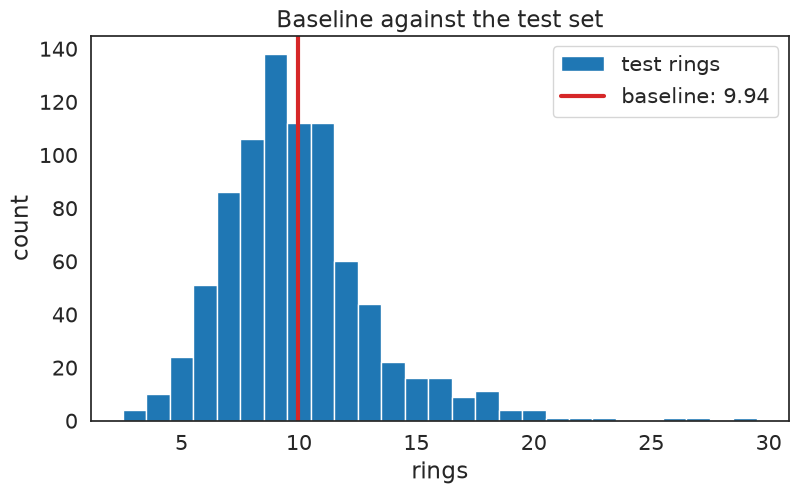

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

baseline = rings.mean()
rings_test = test["rings"].to_numpy()
rmse_test = root_mean_squared_error(rings_test, np.full(len(rings_test), baseline))
mae_test = mean_absolute_error(rings_test, np.full(len(rings_test), baseline))
r2_test = r2_score(rings_test, np.full(len(rings_test), baseline))
print(f"baseline prediction: {baseline:.2f} rings")
print(f"test RMSE {rmse_test:.3f}   MAE {mae_test:.3f}   R² {r2_test:.3f}")

with sns.axes_style("white"), sns.plotting_context("notebook", font_scale=1.4):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(rings_test, bins=np.arange(rings_test.min() - 0.5, rings_test.max() + 1.5, 1), edgecolor="white", label="test rings")
    ax.axvline(baseline, color="C3", lw=3, label=f"baseline: {baseline:.2f}")
    ax.set(title="Baseline against the test set", xlabel="rings", ylabel="count")
    ax.legend()
    plt.show()